# **Clasificación de la forma reportada en avistamientos de OVNIS en Estados Unidos mediante aprendizaje automático**

**Alumno:** Ariel Tuñon

MODELOS DE ENTRENAMIENTO

---

# DATOS LIMPIOS Y PREPARADOS - CARGA DE LIBRERIAS Y DATASET

In [ ]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings('ignore')
import cufflinks as cf
import plotly.offline
cf.go_offline()
cf.set_config_file(offline=False, world_readable=True)

# URL en formato raw corregida (cambiando 'blob' por 'raw')
url_csv = "https://github.com/arieltunon74/Aprendizaje_automatico_parcial_2026/raw/main/data/processed/dataset_procesado.csv"

print("Cargando el dataset procesado desde GitHub...")
# Especificamos sep=';' ya que el archivo utiliza punto y coma como delimitador
df_procesado = pd.read_csv(url_csv, sep=';')

print("\n¡Dataset procesado cargado exitosamente!")
print(f"Total de registros (filas): {df_procesado.shape[0]:,}")
print(f"Total de columnas: {df_procesado.shape[1]}")

Cargando el dataset procesado desde GitHub...

¡Dataset procesado cargado exitosamente!
Total de registros (filas): 79,695
Total de columnas: 25


ESCALADO DE VARIABLES PARA EL MODELO

Target ($y$): shape_grouped

Variables de Entrada Seleccionadas ($X$):Numéricas: duration_seconds, year, month', day_of_week, hour`Categóricas: state_grouped, us_region, north_season, time_of_day, day_category, is_weekend, Duracion_clasificacion, decade

Se aplica ordinal encoder y onehot encoder según el caso. Se excluyen poxsibles variables que provocan data leakage.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

def preparar_datos_ml(ruta_csv='https://github.com/arieltunon74/Aprendizaje_automatico_parcial_2026/raw/main/data/processed/dataset_procesado.csv'):
    # 1. Cargar el dataset
    df = pd.read_csv(ruta_csv, sep=';')

    # 2. Definir la variable objetivo y las características limpias (sin shape, duration ni leakage)
    target = 'shape_grouped'

    features = [
        # Variables numéricas
        'duration_seconds', 'year', 'month', 'day_of_week', 'hour',
        # Variables categóricas / temporales / geográficas seguras
        'state_grouped', 'us_region', 'north_season', 'time_of_day',
        'day_category', 'is_weekend', 'Duracion_clasificacion', 'decade'
    ]

    X = df[features]
    y = df[target]

    # 3. División estricta Train/Test con estratificación (Previene Data Leakage global)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # 4. Definición de subgrupos de columnas según su naturaleza
    numerical_cols = ['duration_seconds', 'year', 'month', 'day_of_week', 'hour']

    ordinal_cols = ['Duracion_clasificacion', 'decade']
    categories_order = [
        ['Muy corto', 'Corto', 'Medio', 'Largo'],                # Orden para Duracion_clasificacion
        ['1960s', '1970s', '1980s', '1990s', '2000s', '2010s']     # Orden para decade
    ]

    nominal_cols = [
        'state_grouped', 'us_region', 'north_season',
        'time_of_day', 'day_category', 'is_weekend'
    ]

    # 5. Construcción de sub-pipelines independientes (imputación ajustada solo en train)
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    ordinal_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ordinal', OrdinalEncoder(
            categories=categories_order,
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ])

    nominal_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    # 6. Integración en un ColumnTransformer global
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numerical_cols),
            ('ord', ordinal_transformer, ordinal_cols),
            ('cat', nominal_transformer, nominal_cols)
        ]
    )

    # 7. Ajuste seguro: fit_transform exclusivamente en Train, transform en Test
    X_train_processed = preprocessor.fit_transform(X_train)
    X_test_processed = preprocessor.transform(X_test)

    print("=== Proceso Finalizado con Éxito ===")
    print(f"Dimensiones X_train procesado: {X_train_processed.shape}")
    print(f"Dimensiones X_test procesado:  {X_test_processed.shape}")
    print(f"Dimensiones y_train:           {y_train.shape}")
    print(f"Dimensiones y_test:            {y_test.shape}")

    return X_train_processed, X_test_processed, y_train, y_test, preprocessor

# Ejecutar la función si se corre el script directamente
if __name__ == '__main__':
    X_train_p, X_test_p, y_train, y_test, preprocessor_fitted = preparar_datos_ml()

=== Proceso Finalizado con Éxito ===
Dimensiones X_train procesado: (63756, 38)
Dimensiones X_test procesado:  (15939, 38)
Dimensiones y_train:           (63756,)
Dimensiones y_test:            (15939,)


# Regresión Logística Multiclase o Multinomial


Accuracy del modelo: 0.3224794529142355

Reporte de Clasificación:
               precision    recall  f1-score   support

      Circle       0.00      0.00      0.00      1816
        Disk       0.00      0.00      0.00       887
    Fireball       0.13      0.00      0.00      1435
       Light       0.27      0.23      0.25      3713
       Other       0.33      0.83      0.48      5177
      Sphere       0.00      0.00      0.00      1198
    Triangle       0.00      0.00      0.00      1713

    accuracy                           0.32     15939
   macro avg       0.11      0.15      0.10     15939
weighted avg       0.18      0.32      0.21     15939



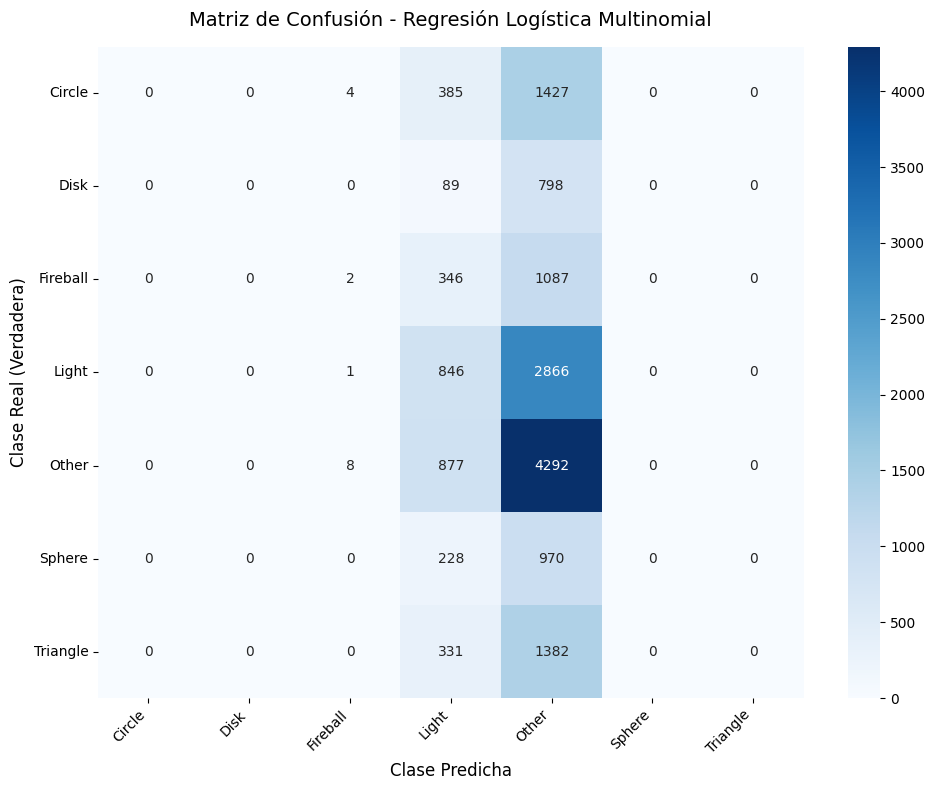

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar el dataset utilizando la URL de GitHub ya definida
url_csv = "https://github.com/arieltunon74/Aprendizaje_automatico_parcial_2026/raw/main/data/processed/dataset_procesado.csv"
df = pd.read_csv(url_csv, sep=';')

target = 'shape_grouped'
features = [
    'duration_seconds', 'year', 'month', 'day_of_week', 'hour',
    'state_grouped', 'us_region', 'north_season', 'time_of_day',
    'day_category', 'is_weekend', 'Duracion_clasificacion', 'decade'
]

X = df[features]
y = df[target]

# 2. División estricta Train/Test (Previene Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Definición de columnas
numerical_cols = ['duration_seconds', 'year', 'month', 'day_of_week', 'hour']
ordinal_cols = ['Duracion_clasificacion', 'decade']
categories_order = [
    ['Muy corto', 'Corto', 'Medio', 'Largo'],
    ['1960s', '1970s', '1980s', '1990s', '2000s', '2010s']
]
nominal_cols = ['state_grouped', 'us_region', 'north_season', 'time_of_day', 'day_category', 'is_weekend']

# 4. Pipelines de transformación interna
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=categories_order, handle_unknown='use_encoded_value', unknown_value=-1))
])

nominal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('ord', ordinal_transformer, ordinal_cols),
        ('cat', nominal_transformer, nominal_cols)
    ]
)

# 5. Pipeline Integrado con Regresión Logística Multinomial
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(multi_class='multinomial', max_iter=1000, random_state=42))
])

# 6. Ajustar (Train) y Predecir (Test)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Obtener probabilidades estimadas para cada clase en el set de prueba
y_proba = model.predict_proba(X_test)

print("Accuracy del modelo:", accuracy_score(y_test, y_pred))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred, zero_division=0))

# ==========================================
# 7. Generación y Visualización de la Matriz de Confusión
# ==========================================

# Calcular la matriz de confusión usando las clases del clasificador entrenado
labels = model.named_steps['classifier'].classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)

# Configurar el gráfico
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,          # Muestra el número exacto en cada celda
    fmt='d',             # Formato entero
    cmap='Blues',        # Paleta de colores
    xticklabels=labels,  # Etiquetas en el eje X (Predicho)
    yticklabels=labels   # Etiquetas en el eje Y (Real)
)

plt.title('Matriz de Confusión - Regresión Logística Multinomial', fontsize=14, pad=15)
plt.xlabel('Clase Predicha', fontsize=12)
plt.ylabel('Clase Real (Verdadera)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# Guardar la imagen y mostrarla en pantalla
plt.savefig('matriz_confusion_multiclase.png', dpi=300)
plt.show()

## Testeo de modelo - Arbol de decisión

Análisis de Resultados - Árbol de Decisión
El modelo de Árbol de Decisión (con una profundidad máxima limitada a 8 para evitar sobreajuste) se ha entrenado y evaluado con éxito. Aquí tienes los aspectos clave del resultado:

Precisión General (Accuracy):

El accuracy es de 32.83%, lo cual representa una ligera mejora en comparación con el modelo de Regresión Logística (~32.25%).
Capacidad de Discriminación entre Clases:

A diferencia de la Regresión Logística (que prácticamente ignoraba la mayoría de las clases), el Árbol de Decisión empieza a identificar patrones en casi todas las clases (con excepción de Sphere).
Circle, Disk, Fireball y Triangle ahora tienen valores mayores a cero tanto en precisión como en recall. Por ejemplo, el modelo detectó correctamente 53 casos de Fireball (con una precisión del 29%) y 11 casos de Disk (con una precisión del 28%).
Las clases Light (recall de 41%) y Other (recall de 70%) siguen dominando las predicciones debido al fuerte desbalance natural de los datos.
Comparación rápida:

El Árbol de Decisión demuestra tener una estructura no lineal que le permite extraer mejores reglas lógicas de las características categóricas y ordinales, logrando un mejor balance en el reporte de clasificación comparado con el modelo lineal de regresión logística.

Accuracy del Árbol de Decisión: 0.3282514586862413

Reporte de Clasificación:
               precision    recall  f1-score   support

      Circle       0.19      0.01      0.01      1816
        Disk       0.28      0.01      0.02       887
    Fireball       0.29      0.04      0.07      1435
       Light       0.29      0.41      0.34      3713
       Other       0.35      0.70      0.47      5177
      Sphere       0.00      0.00      0.00      1198
    Triangle       0.12      0.00      0.01      1713

    accuracy                           0.33     15939
   macro avg       0.22      0.17      0.13     15939
weighted avg       0.26      0.33      0.24     15939



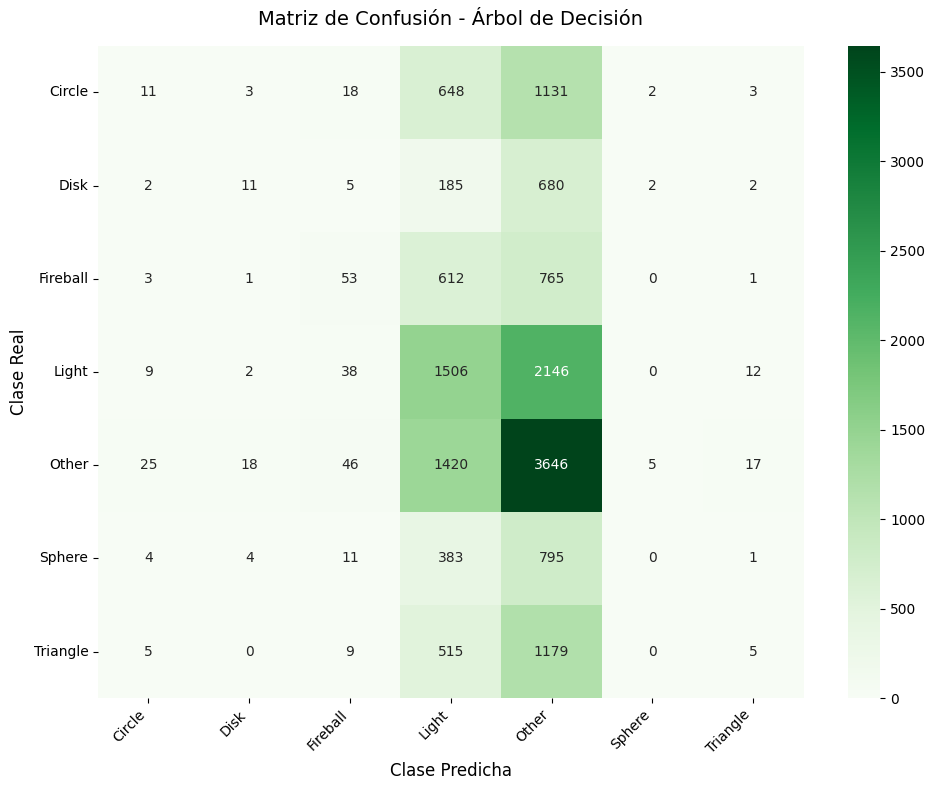

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar el dataset utilizando la URL de GitHub corregida
url_csv = "https://github.com/arieltunon74/Aprendizaje_automatico_parcial_2026/raw/main/data/processed/dataset_procesado.csv"
df = pd.read_csv(url_csv, sep=';')

target = 'shape_grouped'
features = [
    'duration_seconds', 'year', 'month', 'day_of_week', 'hour',
    'state_grouped', 'us_region', 'north_season', 'time_of_day',
    'day_category', 'is_weekend', 'Duracion_clasificacion', 'decade'
]

X = df[features]
y = df[target]

# 2. División estricta Train/Test (Previene Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Definición de columnas
numerical_cols = ['duration_seconds', 'year', 'month', 'day_of_week', 'hour']
ordinal_cols = ['Duracion_clasificacion', 'decade']
categories_order = [
    ['Muy corto', 'Corto', 'Medio', 'Largo'],
    ['1960s', '1970s', '1980s', '1990s', '2000s', '2010s']
]
nominal_cols = ['state_grouped', 'us_region', 'north_season', 'time_of_day', 'day_category', 'is_weekend']

# 4. Pipelines de transformación interna (Imputación y codificación segura)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=categories_order, handle_unknown='use_encoded_value', unknown_value=-1))
])

nominal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('ord', ordinal_transformer, ordinal_cols),
        ('cat', nominal_transformer, nominal_cols)
    ]
)

# 5. Pipeline Integrado con Árbol de Decisión (Limitando max_depth=8 para prevenir sobreajuste)
model_dt = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=8, random_state=42))
])

# 6. Ajustar (Train) y Predecir (Test)
model_dt.fit(X_train, y_train)
y_pred_dt = model_dt.predict(X_test)
y_proba_dt = model_dt.predict_proba(X_test) # Probabilidades de pertenencia a cada clase

print("Accuracy del Árbol de Decisión:", accuracy_score(y_test, y_pred_dt))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred_dt, zero_division=0))

# ==========================================
# 7. Generación y Visualización de la Matriz de Confusión
# ==========================================
labels = model_dt.named_steps['classifier'].classes_
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=labels,
    yticklabels=labels
)
plt.title('Matriz de Confusión - Árbol de Decisión', fontsize=14, pad=15)
plt.xlabel('Clase Predicha', fontsize=12)
plt.ylabel('Clase Real', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('matriz_confusion_arbol.png', dpi=300)
plt.show()

## MODELO RANDOM FOREST

Accuracy de Random Forest (con balanceo): 0.2111173850304285

Reporte de Clasificación:
               precision    recall  f1-score   support

      Circle       0.15      0.12      0.14      1816
        Disk       0.12      0.25      0.16       887
    Fireball       0.18      0.53      0.27      1435
       Light       0.31      0.22      0.25      3713
       Other       0.40      0.15      0.22      5177
      Sphere       0.10      0.07      0.08      1198
    Triangle       0.17      0.30      0.21      1713

    accuracy                           0.21     15939
   macro avg       0.20      0.23      0.19     15939
weighted avg       0.27      0.21      0.21     15939



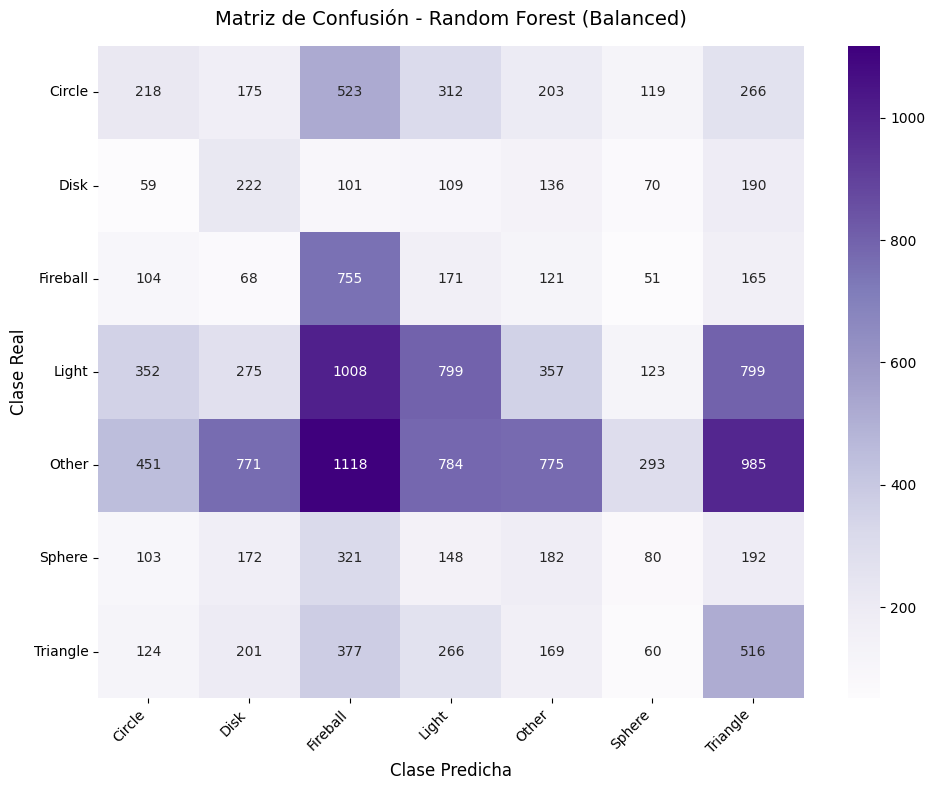

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar el dataset desde la URL de GitHub para evitar FileNotFoundError
url_csv = "https://github.com/arieltunon74/Aprendizaje_automatico_parcial_2026/raw/main/data/processed/dataset_procesado.csv"
df = pd.read_csv(url_csv, sep=';')

target = 'shape_grouped'
features = [
    'duration_seconds', 'year', 'month', 'day_of_week', 'hour',
    'state_grouped', 'us_region', 'north_season', 'time_of_day',
    'day_category', 'is_weekend', 'Duracion_clasificacion', 'decade'
]

X = df[features]
y = df[target]

# 2. División estricta Train/Test (Previene Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Definición de columnas
numerical_cols = ['duration_seconds', 'year', 'month', 'day_of_week', 'hour']
ordinal_cols = ['Duracion_clasificacion', 'decade']
categories_order = [
    ['Muy corto', 'Corto', 'Medio', 'Largo'],
    ['1960s', '1970s', '1980s', '1990s', '2000s', '2010s']
]
nominal_cols = ['state_grouped', 'us_region', 'north_season', 'time_of_day', 'day_category', 'is_weekend']

# 4. Pipelines de transformación interna (Imputación y codificación segura)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=categories_order, handle_unknown='use_encoded_value', unknown_value=-1))
])

nominal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('ord', ordinal_transformer, ordinal_cols),
        ('cat', nominal_transformer, nominal_cols)
    ]
)

# 5. Pipeline Integrado con Random Forest Classifier aplicando class_weight='balanced'
model_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

# 6. Ajustar (Train) y Predecir (Test)
model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)
y_proba_rf = model_rf.predict_proba(X_test)

print("Accuracy de Random Forest (con balanceo):", accuracy_score(y_test, y_pred_rf))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred_rf, zero_division=0))

# ==========================================
# 7. Matriz de Confusión
# ==========================================
labels = model_rf.named_steps['classifier'].classes_
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Purples', xticklabels=labels, yticklabels=labels)
plt.title('Matriz de Confusión - Random Forest (Balanced)', fontsize=14, pad=15)
plt.xlabel('Clase Predicha', fontsize=12)
plt.ylabel('Clase Real', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('matriz_confusion_rf.png', dpi=300)
plt.show()

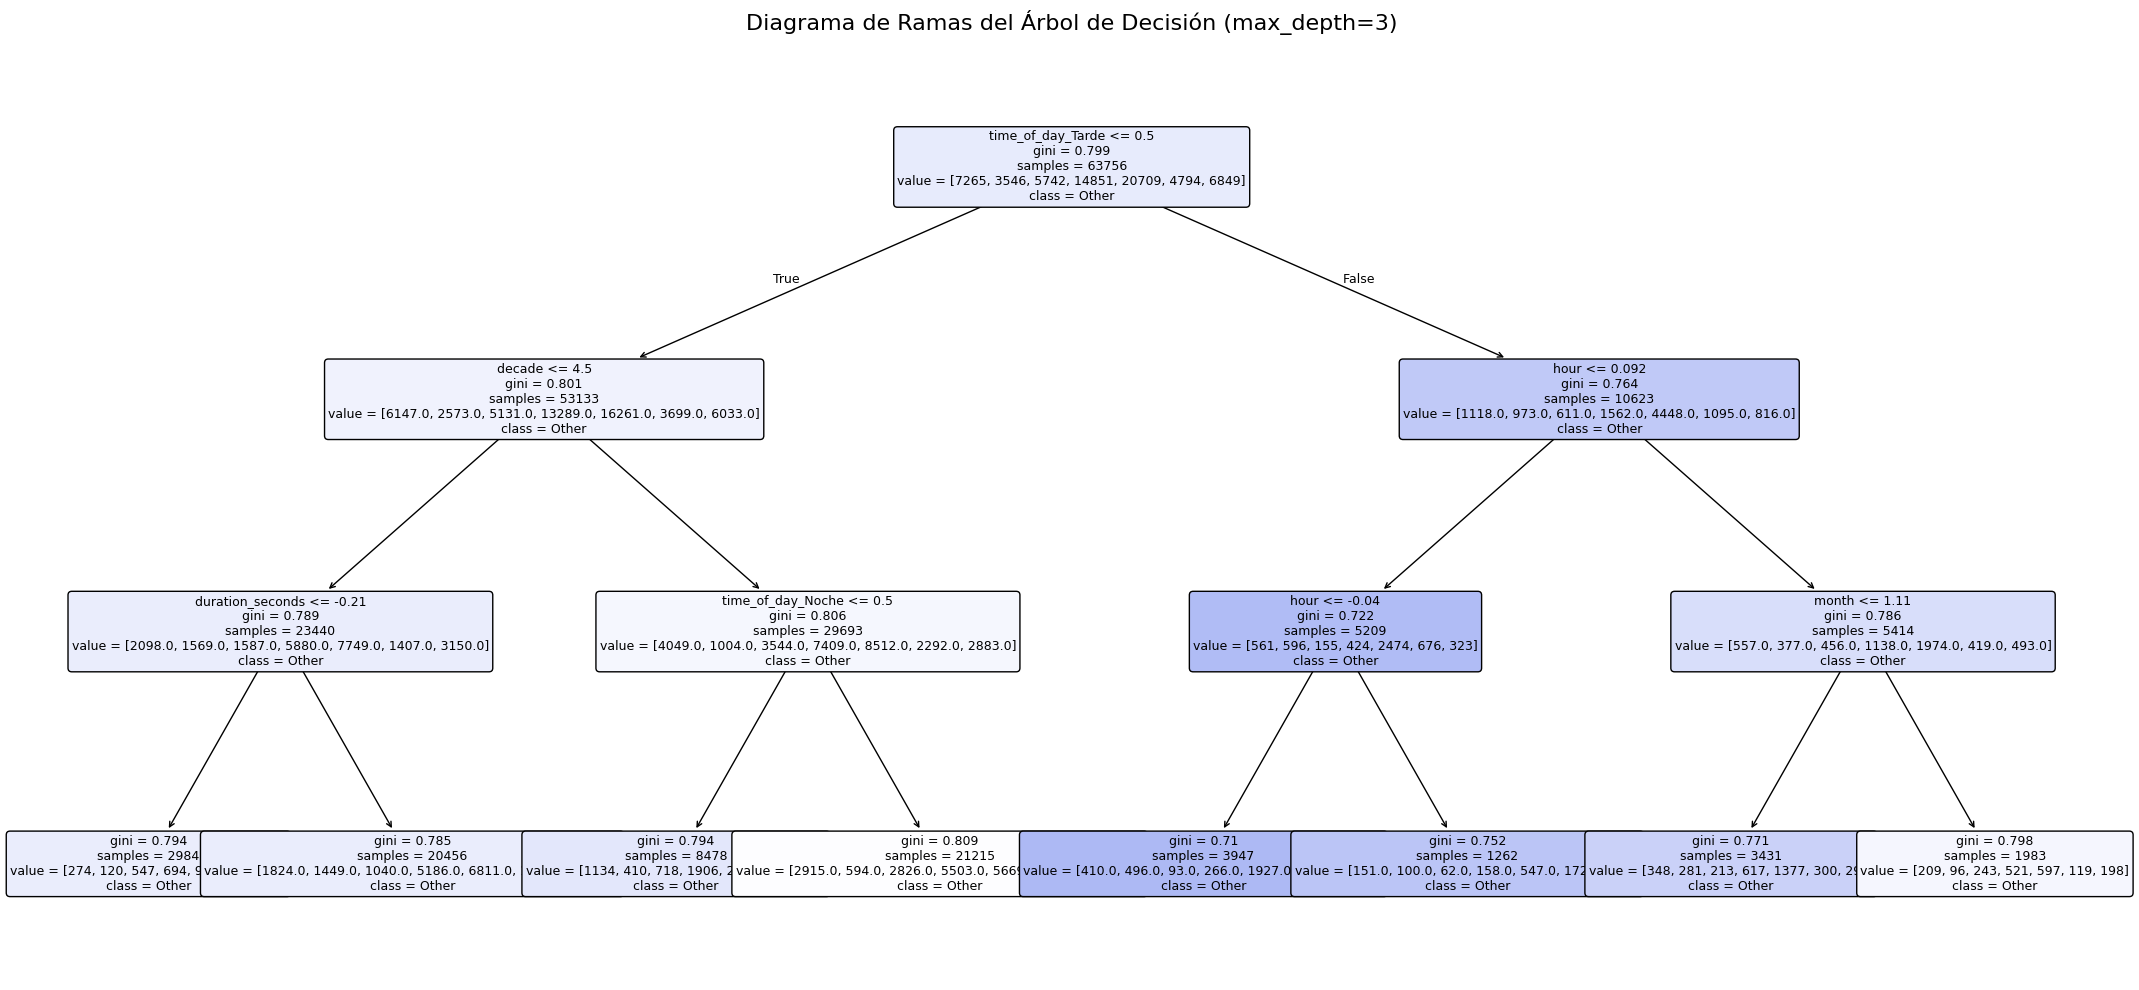

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# 1. Instanciar un modelo con profundidad controlada para visualización clara
model_viz = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=3, random_state=42))
])

# 2. Ajustar con los datos de entrenamiento
model_viz.fit(X_train, y_train)

# 3. Extraer los nombres de todas las características procesadas (numéricas + ordinales + one-hot)
cat_encoder = model_viz.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
encoded_cat_cols = cat_encoder.get_feature_names_out(nominal_cols).tolist()
all_feature_names = numerical_cols + ordinal_cols + encoded_cat_cols

# 4. Generar y guardar el gráfico de ramas
plt.figure(figsize=(22, 10))
plot_tree(
    model_viz.named_steps['classifier'],
    feature_names=all_feature_names,
    class_names=model_viz.named_steps['classifier'].classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Diagrama de Ramas del Árbol de Decisión (max_depth=3)", fontsize=16, pad=15)
plt.tight_layout()
plt.savefig('ramas_arbol_decision.png', dpi=300)
plt.show()

## KNN

Accuracy de KNN: 0.2929920321224669

Reporte de Clasificación (KNN):
               precision    recall  f1-score   support

      Circle       0.14      0.08      0.10      1816
        Disk       0.10      0.02      0.03       887
    Fireball       0.17      0.11      0.13      1435
       Light       0.28      0.37      0.32      3713
       Other       0.35      0.56      0.43      5177
      Sphere       0.09      0.01      0.01      1198
    Triangle       0.13      0.03      0.05      1713

    accuracy                           0.29     15939
   macro avg       0.18      0.17      0.16     15939
weighted avg       0.24      0.29      0.25     15939



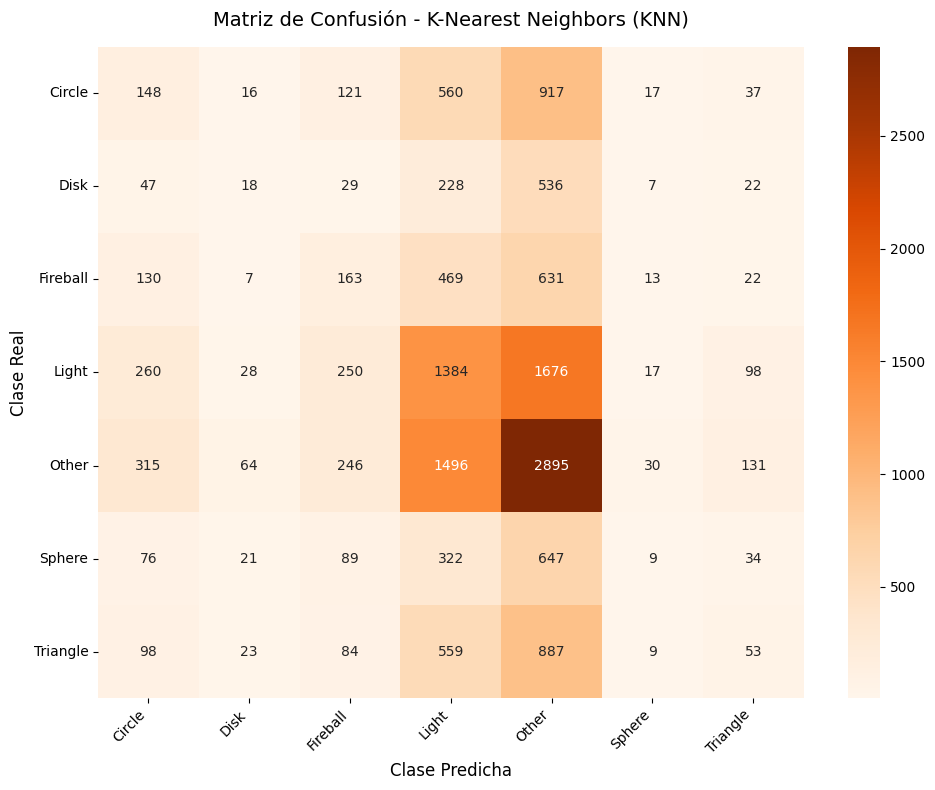

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar el dataset utilizando la URL de GitHub ya definida para evitar FileNotFoundError
url_csv = "https://github.com/arieltunon74/Aprendizaje_automatico_parcial_2026/raw/main/data/processed/dataset_procesado.csv"
df = pd.read_csv(url_csv, sep=';')

target = 'shape_grouped'
features = [
    'duration_seconds', 'year', 'month', 'day_of_week', 'hour',
    'state_grouped', 'us_region', 'north_season', 'time_of_day',
    'day_category', 'is_weekend', 'Duracion_clasificacion', 'decade'
]

X = df[features]
y = df[target]

# 2. División estricta Train/Test (Previene Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Definición de columnas
numerical_cols = ['duration_seconds', 'year', 'month', 'day_of_week', 'hour']
ordinal_cols = ['Duracion_clasificacion', 'decade']
categories_order = [
    ['Muy corto', 'Corto', 'Medio', 'Largo'],
    ['1960s', '1970s', '1980s', '1990s', '2000s', '2010s']
]
nominal_cols = ['state_grouped', 'us_region', 'north_season', 'time_of_day', 'day_category', 'is_weekend']

# 4. Pipelines de transformación interna (imputación + escala ajustada solo en train)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=categories_order, handle_unknown='use_encoded_value', unknown_value=-1))
])

nominal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('ord', ordinal_transformer, ordinal_cols),
        ('cat', nominal_transformer, nominal_cols)
    ]
)

# 5. Pipeline Integrado con K-Nearest Neighbors (k=15 vecinos más cercanos)
model_knn = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=15, n_jobs=-1))
])

# 6. Ajustar (Train) y Predecir (Test)
model_knn.fit(X_train, y_train)
y_pred_knn = model_knn.predict(X_test)
y_proba_knn = model_knn.predict_proba(X_test) # Probabilidades basadas en los k vecinos

print("Accuracy de KNN:", accuracy_score(y_test, y_pred_knn))
print("\nReporte de Clasificación (KNN):\n", classification_report(y_test, y_pred_knn, zero_division=0))

# ==========================================
# 7. Generación y Visualización de la Matriz de Confusión
# ==========================================
labels = model_knn.named_steps['classifier'].classes_
cm_knn = confusion_matrix(y_test, y_pred_knn, labels=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=labels,
    yticklabels=labels
)
plt.title('Matriz de Confusión - K-Nearest Neighbors (KNN)', fontsize=14, pad=15)
plt.xlabel('Clase Predicha', fontsize=12)
plt.ylabel('Clase Real', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('matriz_confusion_knn.png', dpi=300)
plt.show()

## XGBoost (eXtreme Gradient Boosting)

Accuracy de Gradient Boosting: 0.3323295062425497

Reporte de Clasificación:
               precision    recall  f1-score   support

      Circle       0.13      0.00      0.00      1816
        Disk       0.20      0.00      0.01       887
    Fireball       0.30      0.09      0.14      1435
       Light       0.29      0.28      0.28      3713
       Other       0.35      0.80      0.48      5177
      Sphere       0.00      0.00      0.00      1198
    Triangle       0.15      0.00      0.01      1713

    accuracy                           0.33     15939
   macro avg       0.20      0.17      0.13     15939
weighted avg       0.25      0.33      0.24     15939



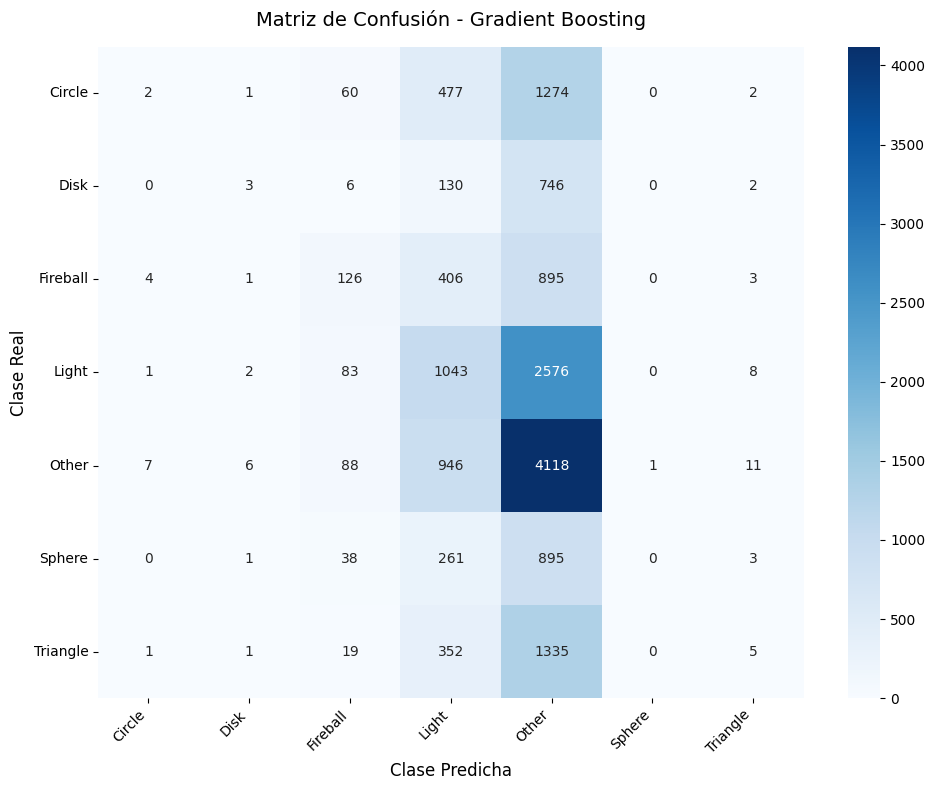

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier # Alternativa nativa optimizada de altas prestaciones
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar el dataset utilizando la URL de GitHub
url_csv = "https://github.com/arieltunon74/Aprendizaje_automatico_parcial_2026/raw/main/data/processed/dataset_procesado.csv"
df = pd.read_csv(url_csv, sep=';')

target = 'shape_grouped'
features = [
    'duration_seconds', 'year', 'month', 'day_of_week', 'hour',
    'state_grouped', 'us_region', 'north_season', 'time_of_day',
    'day_category', 'is_weekend', 'Duracion_clasificacion', 'decade'
]

X = df[features]
y = df[target]

# 2. División estricta Train/Test (Previene Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Definición de columnas
numerical_cols = ['duration_seconds', 'year', 'month', 'day_of_week', 'hour']
ordinal_cols = ['Duracion_clasificacion', 'decade']
categories_order = [
    ['Muy corto', 'Corto', 'Medio', 'Largo'],
    ['1960s', '1970s', '1980s', '1990s', '2000s', '2010s']
]
nominal_cols = ['state_grouped', 'us_region', 'north_season', 'time_of_day', 'day_category', 'is_weekend']

# 4. Pipelines de transformación interna (imputación y escala ajustada solo en train)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=categories_order, handle_unknown='use_encoded_value', unknown_value=-1))
])

nominal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('ord', ordinal_transformer, ordinal_cols),
        ('cat', nominal_transformer, nominal_cols)
    ]
)

# 5. Pipeline Integrado con Gradient Boosting Classifier
model_hgb = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(max_iter=100, random_state=42))
])

# 6. Ajustar (Train) y Predecir (Test)
model_hgb.fit(X_train, y_train)
y_pred_hgb = model_hgb.predict(X_test)
y_proba_hgb = model_hgb.predict_proba(X_test) # Probabilidades estimadas para cada clase

print("Accuracy de Gradient Boosting:", accuracy_score(y_test, y_pred_hgb))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred_hgb, zero_division=0))

# ==========================================
# 7. Generación y Visualización de la Matriz de Confusión
# ==========================================
labels = model_hgb.named_steps['classifier'].classes_
cm_hgb = confusion_matrix(y_test, y_pred_hgb, labels=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_hgb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)
plt.title('Matriz de Confusión - Gradient Boosting', fontsize=14, pad=15)
plt.xlabel('Clase Predicha', fontsize=12)
plt.ylabel('Clase Real', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('matriz_confusion_xgb.png', dpi=300)
plt.show()

## RESULTADOS ENTRE LOS MODELOS

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Importación de los clasificadores
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

# Métricas de evaluación
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def ejecutar_comparativa_modelos(ruta_csv='https://github.com/arieltunon74/Aprendizaje_automatico_parcial_2026/raw/main/data/processed/dataset_procesado.csv'):
    print("1. Cargando datos y aplicando división train/test limpia...")
    df = pd.read_csv(ruta_csv, sep=';')

    # Variable objetivo y características seleccionadas
    target = 'shape_grouped'
    features = [
        'duration_seconds', 'year', 'month', 'day_of_week', 'hour',
        'state_grouped', 'us_region', 'north_season', 'time_of_day',
        'day_category', 'is_weekend', 'Duracion_clasificacion', 'decade'
    ]

    X = df[features]
    y = df[target]

    # División estricta de conjuntos para evitar Data Leakage
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # 2. Definición del Preprocesamiento
    numerical_cols = ['duration_seconds', 'year', 'month', 'day_of_week', 'hour']
    ordinal_cols = ['Duracion_clasificacion', 'decade']
    categories_order = [
        ['Muy corto', 'Corto', 'Medio', 'Largo'],
        ['1960s', '1970s', '1980s', '1990s', '2000s', '2010s']
    ]
    nominal_cols = ['state_grouped', 'us_region', 'north_season', 'time_of_day', 'day_category', 'is_weekend']

    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    ordinal_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ordinal', OrdinalEncoder(categories=categories_order, handle_unknown='use_encoded_value', unknown_value=-1))
    ])

    nominal_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numerical_cols),
            ('ord', ordinal_transformer, ordinal_cols),
            ('cat', nominal_transformer, nominal_cols)
        ]
    )

    # 3. Definición del Diccionario de Modelos a comparar
    models = {
        'Regresión Logística': LogisticRegression(multi_class='multinomial', max_iter=1000, random_state=42),
        'Árbol de Decisión (depth=8)': DecisionTreeClassifier(max_depth=8, random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1),
        'Gradient Boosting': HistGradientBoostingClassifier(max_iter=100, random_state=42),
        'KNN (k=15)': KNeighborsClassifier(n_neighbors=15, n_jobs=-1)
    }

    resultados_lista = []

    print("2. Entrenando modelos y calculando métricas...\n")
    for nombre, clf in models.items():
        # Construir Pipeline completo (Preprocesamiento + Clasificador)
        pipeline = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', clf)
        ])

        # Ajustar únicamente en entrenamiento
        pipeline.fit(X_train, y_train)

        # Predecir en prueba
        y_pred = pipeline.predict(X_test)

        # Calcular métricas globales
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
        rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
        f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

        resultados_lista.append({
            'Modelo': nombre,
            'Accuracy': acc,
            'Precision (Weighted)': prec,
            'Recall (Weighted)': rec,
            'F1-Score (Weighted)': f1
        })

        # Generar y guardar Matriz de Confusión para cada modelo
        clases = pipeline.named_steps['classifier'].classes_
        cm = confusion_matrix(y_test, y_pred, labels=clases)

        plt.figure(figsize=(9, 7))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=clases, yticklabels=clases)
        plt.title(f'Matriz de Confusión - {nombre}', fontsize=14, pad=15)
        plt.xlabel('Clase Predicha', fontsize=12)
        plt.ylabel('Clase Real', fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.yticks(rotation=0)
        plt.tight_layout()

        nombre_archivo = f"matriz_confusion_{nombre.replace(' ', '_').replace('(', '').replace(')', '').replace('=', '_')}.png"
        plt.savefig(nombre_archivo, dpi=300)
        plt.close()

    # 4. Presentar la Tabla Comparativa Final
    df_resultados = pd.DataFrame(resultados_lista).sort_values(by='Accuracy', ascending=False)

    print("=== TABLA COMPARATIVA DE RENDIMIENTO ===")
    print(df_resultados.to_string(index=False))

    return df_resultados

if __name__ == '__main__':
    tabla_comparativa = ejecutar_comparativa_modelos()

1. Cargando datos y aplicando división train/test limpia...
2. Entrenando modelos y calculando métricas...



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


=== TABLA COMPARATIVA DE RENDIMIENTO ===
                     Modelo  Accuracy  Precision (Weighted)  Recall (Weighted)  F1-Score (Weighted)
              Random Forest  0.333710              0.259363           0.333710             0.231527
          Gradient Boosting  0.332330              0.249323           0.332330             0.236985
Árbol de Decisión (depth=8)  0.328251              0.257642           0.328251             0.239914
        Regresión Logística  0.322479              0.184259           0.322479             0.212987
                 KNN (k=15)  0.292992              0.236357           0.292992             0.246688
